# 13. Orthogonal Projection, Least Squares and the Pseudoinverse
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The four fundamental subspaces of an $m\times n$ matrix $A$ of rank $r$, drawn schematically. In $\R^n$ (left) the row space and null space are perpendicular and fill the space; in $\R^m$ (right) so are the column space and left null space. $A$ maps the row space one-to-one onto the column space (blue), sends the null space to $0$ (red), and $x=x_r+x_n$ goes to $Ax=Ax_r$.

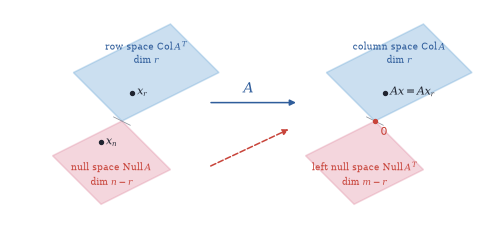

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for ax, (t1, t2, d1, d2) in zip(axs, [(r"row space $\mathrm{Col}\,A^{T}$", r"null space $\mathrm{Null}\,A$", "$r$", "$n-r$"),
                                    (r"column space $\mathrm{Col}\,A$", r"left null space $\mathrm{Null}\,A^{T}$", "$r$", "$m-r$")]):
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect("equal"); ax.axis("off")
    ax.fill([0, 1.4, 0.7, -0.7], [0, 0.7, 1.4, 0.7], color=SKY, alpha=0.35)
    ax.fill([0, -1.0, -0.3, 0.7], [0, -0.5, -1.2, -0.7], color=ROSE, alpha=0.35)
    ax.text(0.35, 1.02, t1, fontsize=6.2, ha="center", color=BLUE); ax.text(0.35, 0.84, "dim " + d1, fontsize=6, ha="center", color=BLUE)
    ax.text(-0.15, -0.72, t2, fontsize=6.2, ha="center", color=RED); ax.text(-0.15, -0.92, "dim " + d2, fontsize=6, ha="center", color=RED)
    ax.plot([-0.12, 0.0, 0.12], [0.06, 0.0, -0.06], color=GRAY, lw=0.5)
axs[0].plot(0.15, 0.4, "o", color=INK, ms=2.5); axs[0].text(0.22, 0.38, "$x_r$", fontsize=7)
axs[0].plot(-0.3, -0.3, "o", color=INK, ms=2.5); axs[0].text(-0.23, -0.34, "$x_n$", fontsize=7)
axs[1].plot(0.15, 0.4, "o", color=INK, ms=2.5); axs[1].text(0.22, 0.38, "$Ax=Ax_r$", fontsize=7)
axs[1].plot(0, 0, "o", color=RED, ms=2.5); axs[1].text(0.08, -0.2, "$0$", fontsize=7, color=RED)
fig.text(0.5, 0.62, r"$A$", ha="center", fontsize=9, color=BLUE)
fig.patches.append(plt.matplotlib.patches.FancyArrowPatch((0.42, 0.58), (0.6, 0.58), transform=fig.transFigure, arrowstyle="-|>", mutation_scale=8, color=BLUE))
fig.patches.append(plt.matplotlib.patches.FancyArrowPatch((0.42, 0.3), (0.585, 0.47), transform=fig.transFigure, arrowstyle="-|>", mutation_scale=8, color=RED, ls="--"))

Left, orthogonal projection of $v$ onto a plane $U\subset\R^3$: the error $v-P_Uv$ (red) is perpendicular to $U$, and $P_Uv$ is the point of $U$ closest to $v$. Right, in $\R^2$, the orthogonal projection onto a line (blue) and an oblique projection onto the same line along a slanted direction (gold). Both satisfy $P^2=P$; only the orthogonal one is symmetric and shrinks every vector.

Text(0.24496855345911972, 0.5382389937106917, 'oblique')

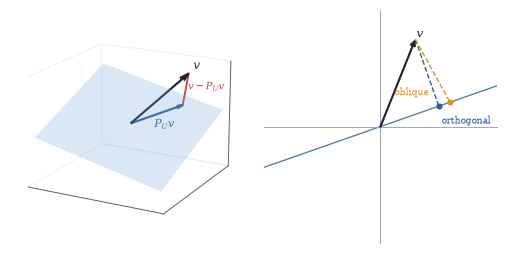

In [3]:
fig = plt.figure(figsize=(W, 2.2))
ax = ax3d(fig, 121, elev=18, azim=-62, lim=1.4)
n = np.array([0.3, -0.4, 1.0]); n /= np.linalg.norm(n)
plane3d(ax, n, lim=1.3)
v = np.array([0.9, 0.6, 1.25]); p = v - (v @ n) * n
arrow3d(ax, v, color=INK, label="$v$"); arrow3d(ax, p, color=BLUE); ax.text(*(0.45 * p + [0.0, 0.0, -0.32]), "$P_Uv$", color=BLUE, fontsize=7)
ax.plot(*np.c_[p, v], color=RED, lw=1.2); ax.text(*(0.5 * (p + v) + [0.05, 0, 0]), "$v-P_Uv$", color=RED, fontsize=6.5)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
ax2 = fig.add_subplot(122); plane(ax2, 2.0, grid=False)
u = np.array([1.0, 0.35]); u /= np.linalg.norm(u); span_line(ax2, u, lim=2.0, color=BLUE)
v2 = np.array([0.6, 1.5]); po = (v2 @ u) * u
d = np.array([-0.55, 1.0]); M = np.c_[u, d]; c = np.linalg.solve(M, v2); pb = c[0] * u
arrow(ax2, v2, color=INK, label="$v$")
ax2.plot(*np.c_[v2, po], color=BLUE, ls="--", lw=0.9); ax2.plot(*po, "o", color=BLUE, ms=3)
ax2.plot(*np.c_[v2, pb], color=GOLD, ls="--", lw=0.9); ax2.plot(*pb, "o", color=GOLD, ms=3)
ax2.text(po[0] + 0.05, po[1] - 0.3, "orthogonal", color=BLUE, fontsize=6); ax2.text(pb[0] - 0.95, pb[1] + 0.12, "oblique", color=GOLD, fontsize=6)

In [4]:
rng = np.random.default_rng(3)
A = rng.normal(size=(6, 3))
P1 = A @ np.linalg.solve(A.T @ A, A.T)          # A (A^T A)^{-1} A^T
Q, _ = np.linalg.qr(A); P2 = Q @ Q.T              # Q Q^T
print("same projection:", np.allclose(P1, P2), "  P^2 = P:", np.allclose(P1 @ P1, P1), "  P^T = P:", np.allclose(P1, P1.T))
print("trace(P) = rank =", round(np.trace(P1), 10), "   eigenvalues:", np.round(np.linalg.eigvalsh(P1), 10))

same projection: True   P^2 = P: True   P^T = P: True
trace(P) = rank = 3.0    eigenvalues: [-0. -0.  0.  1.  1.  1.]


Approximating $\sin x$ on $[-\pi,\pi]$ by quintics. Left: the $L^2$ projection (blue) is indistinguishable from $\sin x$ (grey); the Taylor polynomial (gold) drifts away beyond $\lvert x\rvert\approx2$. Right: the errors on a logarithmic scale. Projection spreads a uniformly tiny error over the interval; Taylor is perfect at $0$ and bad at the ends.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


coefficients of x, x^3, x^5: [ 0.987861 -0.15527   0.005643]


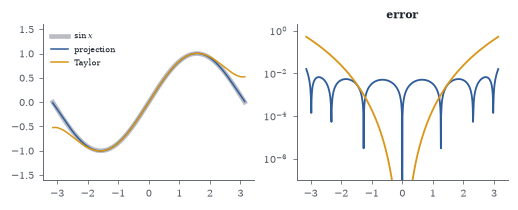

In [5]:
x = np.linspace(-np.pi, np.pi, 801); dx = x[1] - x[0]
w = np.full_like(x, dx); w[[0, -1]] = dx / 2                          # trapezoid weights
B = np.vander(x, 6, increasing=True)
G = B.T @ (w[:, None] * B); rhs = B.T @ (w * np.sin(x))
c = np.linalg.solve(G, rhs); p = B @ c
taylor = x - x ** 3 / 6 + x ** 5 / 120
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8))
axs[0].plot(x, np.sin(x), color=GRAY, lw=3, alpha=0.6, label=r"$\sin x$")
axs[0].plot(x, p, color=BLUE, lw=1, label="projection"); axs[0].plot(x, taylor, color=GOLD, lw=1, label="Taylor")
axs[0].set_ylim(-1.6, 1.6); axs[0].legend(fontsize=5.5)
axs[1].semilogy(x, np.abs(p - np.sin(x)) + 1e-12, color=BLUE); axs[1].semilogy(x, np.abs(taylor - np.sin(x)) + 1e-12, color=GOLD)
axs[1].set_ylim(1e-7, 2); axs[1].set_title("error", fontsize=7)
print("coefficients of x, x^3, x^5:", np.round(c[[1, 3, 5]], 6))

Two pictures of the same least squares fit. Left, in the $t$–$b$ plane: four data points, the best line $b=1+4t$ and the vertical errors $e_i$ whose squares sum to $44$. Right, in $\R^4$, schematically: the data vector $b$, its projection $p$ onto the plane $\mathrm{Col}\,A$ spanned by $a_1=(1,1,1,1)$ and $a_2=(0,1,3,4)$, and the error $e\perp\mathrm{Col}\,A$, a right triangle with $\lVert b\rVert^2=\lVert p\rVert^2+\lVert e\rVert^2$.

C, D = 1.0 4.0   p = [ 1.  5. 13. 17.]   e = [-1.  3. -5.  3.]   |e|^2 = 44.0   A^T e = [0. 0.]


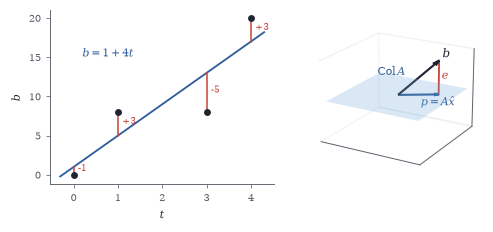

In [6]:
t = np.array([0, 1, 3, 4.]); b = np.array([0, 8, 8, 20.])
A = np.c_[np.ones(4), t]; C, D = np.linalg.solve(A.T @ A, A.T @ b); p = A @ [C, D]
fig = plt.figure(figsize=(W, 2.0))
ax = fig.add_subplot(121)
tt = np.linspace(-0.3, 4.3, 2); ax.plot(tt, C + D * tt, color=BLUE, lw=1.2)
for ti, bi, pi in zip(t, b, p):
    ax.plot([ti, ti], [bi, pi], color=RED, lw=1); ax.text(ti + 0.1, (bi + pi) / 2, f"{bi - pi:+.0f}", color=RED, fontsize=6)
ax.plot(t, b, "o", color=INK, ms=3.5); ax.set_xlabel("$t$"); ax.set_ylabel("$b$"); ax.text(0.2, 15, "$b=1+4t$", color=BLUE, fontsize=7)
ax2 = ax3d(fig, 122, elev=20, azim=-60, lim=1.3)
plane3d(ax2, [0, 0, 1], lim=1.2); bb = np.array([0.8, 0.5, 1.1]); pp = np.array([0.8, 0.5, 0])
arrow3d(ax2, bb, color=INK, label="$b$"); arrow3d(ax2, pp, color=BLUE)
ax2.text(0.55, 0.1, -0.25, "$p=A\\hat x$", color=BLUE, fontsize=7)
ax2.plot(*np.c_[pp, bb], color=RED, lw=1.2); ax2.text(0.85, 0.55, 0.5, "$e$", color=RED, fontsize=7)
ax2.text(-1.1, 0.9, 0.02, r"$\mathrm{Col}\,A$", color=BLUE, fontsize=7); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
print("C, D =", C, D, "  p =", p, "  e =", b - p, "  |e|^2 =", (b - p) @ (b - p), "  A^T e =", A.T @ (b - p))

Relative error in the computed least squares solution for polynomial fitting with monomial bases of increasing degree (a notoriously ill-conditioned problem), against $\kappa(A)$. Normal equations (red) lose accuracy like $\kappa^2\varepsilon$ and are useless beyond $\kappa\approx10^8$; Householder QR (blue) and the SVD-based solver (gold) degrade only like $\kappa\varepsilon$. The dashed lines are $\kappa\varepsilon$ and $\kappa^2\varepsilon$.

(1e-17, 100.0)

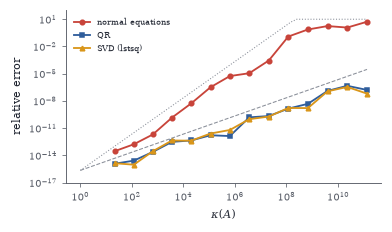

In [7]:
rng = np.random.default_rng(0); eps = np.finfo(float).eps
rows = []
for deg in range(2, 16):
    x = np.linspace(0, 1, 60); A = np.vander(x, deg + 1, increasing=True)
    xt = rng.normal(size=deg + 1); bvec = A @ xt
    kap = np.linalg.cond(A)
    xn = np.linalg.solve(A.T @ A, A.T @ bvec)
    Q, R = np.linalg.qr(A); xq = np.linalg.solve(R, Q.T @ bvec)
    xs = np.linalg.lstsq(A, bvec, rcond=None)[0]
    err = lambda z: np.linalg.norm(z - xt) / np.linalg.norm(xt)
    rows.append((kap, err(xn), err(xq), err(xs)))
r = np.array(rows)
fig, ax = plt.subplots(figsize=(W * 0.75, 2.0))
ax.loglog(r[:, 0], r[:, 1], "o-", color=RED, ms=3, label="normal equations")
ax.loglog(r[:, 0], r[:, 2], "s-", color=BLUE, ms=3, label="QR")
ax.loglog(r[:, 0], r[:, 3], "^-", color=GOLD, ms=3, label="SVD (lstsq)")
k = np.logspace(0, np.log10(r[:, 0].max()), 50)
ax.loglog(k, k * eps, "--", color=GRAY, lw=0.7); ax.loglog(k, np.minimum(k ** 2 * eps, 10), ":", color=GRAY, lw=0.7)
ax.set_xlabel(r"$\kappa(A)$"); ax.set_ylabel("relative error"); ax.legend(fontsize=5.5); ax.set_ylim(1e-17, 1e2)

In [8]:
from scipy.linalg import qr
rng = np.random.default_rng(1)
B = rng.normal(size=(50, 3)); A = np.c_[B, B @ [1, 2, 0] + 1e-9 * rng.normal(size=50), B[:, 0] * 3]   # rank 3 up to 1e-9
Q, R, piv = qr(A, pivoting=True)
print("column order chosen:", piv, "\n|diag R| =", np.abs(np.diag(R)).round(12))

column order chosen: [4 3 2 1 0] 
|diag R| = [1.85184401e+01 1.25442825e+01 6.17456817e+00 3.35500000e-09
 0.00000000e+00]


In [9]:
T = np.array([[1, 1, 1, 0], [0, 0, 2, 1], [0, 0, 0, 0.]])
Tp = np.array([[5, -2, 0], [5, -2, 0], [1, 4, 0], [-2, 3, 0]]) / 11
print("matches numpy pinv:", np.allclose(Tp, np.linalg.pinv(T)))
print("Penrose conditions:", np.allclose(T @ Tp @ T, T), np.allclose(Tp @ T @ Tp, Tp),
      np.allclose((T @ Tp).T, T @ Tp), np.allclose((Tp @ T).T, Tp @ T))

matches numpy pinv: True
Penrose conditions: True True True True


The pseudoinverse is discontinuous where the rank drops. Left: the $(2,2)$ entry of $\mathrm{diag}(1,\varepsilon)^\dagger$ as $\varepsilon\to0$ (blue), which is $1/\varepsilon$ until it falls to $0$ at $\varepsilon=0$, and of the ridge approximation $\varepsilon/(\varepsilon^2+\delta)$ for two values of $\delta$ (gold, red), which are continuous and bounded by $1/(2\sqrt\delta)$. Right: for a rank-deficient $A$, the ridge solutions $x_\delta$ converge to the minimum-norm solution $A^\dagger b$ as $\delta\to0$, until rounding error takes over near $\delta=10^{-7}$.

Text(0, 0.5, '$\\|x_\\delta-A^\\dagger b\\|$')

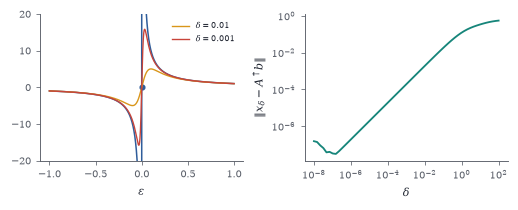

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8))
e = np.linspace(-1, 1, 2001); e = e[e != 0]
axs[0].plot(e, 1 / e, color=BLUE, lw=1); axs[0].plot(0, 0, "o", color=BLUE, ms=3)
for dl, col in [(1e-2, GOLD), (1e-3, RED)]:
    axs[0].plot(e, e / (e ** 2 + dl), color=col, lw=0.9, label=rf"$\delta={dl:g}$")
axs[0].set_ylim(-20, 20); axs[0].legend(fontsize=5.5); axs[0].set_xlabel(r"$\varepsilon$")
rng = np.random.default_rng(2); Ar = rng.normal(size=(8, 3)) @ rng.normal(size=(3, 6)); br = rng.normal(size=8)
xp = np.linalg.pinv(Ar) @ br; ds = np.logspace(-8, 2, 60)
dist = [np.linalg.norm(np.linalg.solve(Ar.T @ Ar + d * np.eye(6), Ar.T @ br) - xp) for d in ds]
axs[1].loglog(ds, dist, color=TEAL); axs[1].set_xlabel(r"$\delta$"); axs[1].set_ylabel(r"$\|x_\delta-A^\dagger b\|$")

Double descent. Test error of minimum-norm least squares (blue) using the first $p$ of $400$ relevant attributes, trained on $m=40$ noisy examples and averaged over $50$ draws; the interpolation threshold $p=m$ is marked. The error explodes where the data matrix is square, then descends a second time, ending below the best underparameterized fit. A ridge penalty (gold) tames the peak. The grey curve is $1/\sigma_{\min}(A)^2$, the noise amplification of $A^\dagger$, on its own scale.

(3, 30000.0)

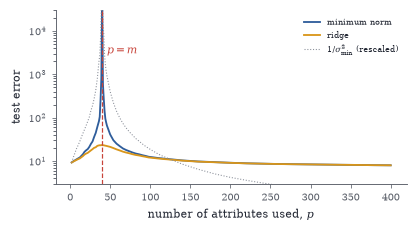

In [11]:
rng = np.random.default_rng(0); m, P = 40, 400; beta = np.ones(P) * 3 / np.sqrt(P)
ps = np.unique(np.r_[np.arange(2, 36, 2), np.arange(36, 46), np.arange(46, 120, 4), np.arange(120, 401, 20)])
err0, err1, amp = np.zeros(len(ps)), np.zeros(len(ps)), np.zeros(len(ps))
for trial in range(50):
    Z = rng.normal(size=(m, P)); y = Z @ beta + 0.5 * rng.normal(size=m); Zt = rng.normal(size=(300, P)); yt = Zt @ beta
    for i, pf in enumerate(ps):
        A = Z[:, :pf]; th = np.linalg.pinv(A) @ y; thr = np.linalg.solve(A.T @ A + 2 * np.eye(pf), A.T @ y)
        err0[i] += np.mean((Zt[:, :pf] @ th - yt) ** 2) / 50; err1[i] += np.mean((Zt[:, :pf] @ thr - yt) ** 2) / 50
        amp[i] += np.linalg.svd(A, compute_uv=False)[min(m, pf) - 1] ** -2 / 50
fig, ax = plt.subplots(figsize=(W * 0.8, 2.0))
ax.semilogy(ps, err0, color=BLUE, lw=1.2, label="minimum norm"); ax.semilogy(ps, err1, color=GOLD, lw=1.2, label="ridge")
ax.semilogy(ps, amp * err0[0] / amp[0], color=GRAY, lw=0.7, ls=":", label=r"$1/\sigma_{\min}^2$ (rescaled)")
ax.axvline(m, color=RED, ls="--", lw=0.8); ax.text(m + 6, 3e3, "$p=m$", color=RED, fontsize=7)
ax.set_xlabel("number of attributes used, $p$"); ax.set_ylabel("test error"); ax.legend(fontsize=5.5); ax.set_ylim(3, 3e4)

In [12]:
E = np.array([[1, 2, 3, -4], [-77, 56, 39, 38], [-3, -9, 7, 0], [151, 36, 111, 139.]])
E = E / np.linalg.norm(E, axis=1, keepdims=True)
print("orthonormal basis of R^4:", np.allclose(E @ E.T, np.eye(4)))

orthonormal basis of R^4: True


In [13]:
import sympy as sp
x = sp.symbols("x"); c = sp.symbols("c1 c3 c5"); p = c[0] * x + c[1] * x ** 3 + c[2] * x ** 5
E = sp.integrate((sp.sin(x) - p) ** 2, (x, -sp.pi, sp.pi))
sol = sp.solve([sp.diff(E, ck) for ck in c], c)
for ck in c: print(ck, "=", sp.factor(sol[ck]), "≈", sp.N(sol[ck], 9))

c1 = 105*(-153*pi**2 + pi**4 + 1485)/(8*pi**6) ≈ 0.987862136
c3 = -315*(-125*pi**2 + pi**4 + 1155)/(4*pi**8) ≈ -0.155271411
c5 = 693*(-105*pi**2 + pi**4 + 945)/(8*pi**10) ≈ 0.00564311798


Fits of increasing degree to the four points. The squared error falls from $204$ (constant) to $44$ (line) to $40$ (parabola) to $0$ (cubic, which interpolates). Each fit is the projection of $b$ onto a larger subspace of $\R^4$, so the error can only decrease, but the interpolating cubic is the least believable of all.

(-6.0, 26.0)

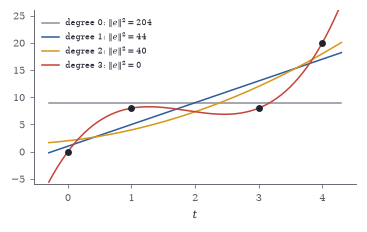

In [14]:
t = np.array([0, 1, 3, 4.]); b = np.array([0, 8, 8, 20.]); tt = np.linspace(-0.3, 4.3, 200)
fig, ax = plt.subplots(figsize=(W * 0.7, 2.0))
for deg, col in [(0, GRAY), (1, BLUE), (2, GOLD), (3, RED)]:
    A = np.vander(t, deg + 1, increasing=True); x = np.linalg.lstsq(A, b, rcond=None)[0]
    E = np.sum((A @ x - b) ** 2)
    ax.plot(tt, np.vander(tt, deg + 1, increasing=True) @ x, color=col, lw=1, label=f"degree {deg}: $\\|e\\|^2={E:.0f}$")
ax.plot(t, b, "o", color=INK, ms=3.5); ax.legend(fontsize=5.5); ax.set_xlabel("$t$"); ax.set_ylim(-6, 26)

In [15]:
A = np.array([[1, 1, 0], [0, 1, 1], [1, 0, -1.]]); b = np.ones(3)
print("A^+ b =", np.linalg.pinv(A) @ b, "   residual direction:", (b - A @ np.linalg.pinv(A) @ b) * 3)

A^+ b = [6.66666667e-01 6.66666667e-01 3.33066907e-16]    residual direction: [-1.  1.  1.]
